In [2]:
from langchain_openai import ChatOpenAI
from langchain_community.document_loaders import PyMuPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_core.documents import Document
from dotenv import load_dotenv
load_dotenv()
from langgraph.graph import StateGraph, START, END
from typing_extensions import TypedDict, List
from langchain_core.messages import SystemMessage, HumanMessage

d:\AI\VS CODE\Langchain\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Tanishk\AppData\Local\Temp\ipykernel_4872\2149845738.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyMuPDFLoader


In [3]:
model=ChatOpenAI(model='gpt-5-mini', temperature=0)
emb=HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3353.15it/s]


In [26]:
loader=PyMuPDFLoader("D:\Volume C\Downloads\Books\COCOMO_MODEL.pdf")
docs=loader.load()

In [27]:
docs

[Document(metadata={'producer': 'Microsoft: Print To PDF', 'creator': '', 'creationdate': '2025-11-14T13:26:04+05:30', 'source': 'D:\\Volume C\\Downloads\\Books\\COCOMO_MODEL.pdf', 'file_path': 'D:\\Volume C\\Downloads\\Books\\COCOMO_MODEL.pdf', 'total_pages': 7, 'format': 'PDF 1.7', 'title': 'Microsoft Word - COCOMO Model', 'author': '', 'subject': '', 'keywords': '', 'moddate': '2025-11-14T13:26:04+05:30', 'trapped': '', 'modDate': "D:20251114132604+05'30'", 'creationDate': "D:20251114132604+05'30'", 'page': 0}, page_content='COCOMO Model \n \nThe Constructive Cost Model (COCOMO) It was proposed by Barry Boehm in 1981 and is \nbased on the study of 63 projects, which makes it one of the best-documented models.  \nIt is a Software Cost Estimation Model that helps predict the effort, cost, and schedule required \nfor a software development project. \n \nCOCOMO Model \nCOCOMO Model is a procedural cost estimate model for Software Projects and is often used as \na process of reliably pre

In [30]:
splitter=RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
splitted_docs=splitter.split_documents(docs)

In [31]:
splitted_docs

[Document(metadata={'producer': 'Microsoft: Print To PDF', 'creator': '', 'creationdate': '2025-11-14T13:26:04+05:30', 'source': 'D:\\Volume C\\Downloads\\Books\\COCOMO_MODEL.pdf', 'file_path': 'D:\\Volume C\\Downloads\\Books\\COCOMO_MODEL.pdf', 'total_pages': 7, 'format': 'PDF 1.7', 'title': 'Microsoft Word - COCOMO Model', 'author': '', 'subject': '', 'keywords': '', 'moddate': '2025-11-14T13:26:04+05:30', 'trapped': '', 'modDate': "D:20251114132604+05'30'", 'creationDate': "D:20251114132604+05'30'", 'page': 0}, page_content='COCOMO Model \n \nThe Constructive Cost Model (COCOMO) It was proposed by Barry Boehm in 1981 and is \nbased on the study of 63 projects, which makes it one of the best-documented models.  \nIt is a Software Cost Estimation Model that helps predict the effort, cost, and schedule required \nfor a software development project. \n \nCOCOMO Model \nCOCOMO Model is a procedural cost estimate model for Software Projects and is often used as'),
 Document(metadata={'pro

In [32]:
vector=FAISS.from_documents(embedding=emb, documents=splitted_docs)
ret=vector.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [33]:
class schema(TypedDict):
    ques:str
    context:List[Document]
    answer:str

In [34]:
def retriever(state:schema)->dict:
    qs=state['ques']
    rs=ret.invoke(qs)
    return {'context':rs}

In [35]:
def generate(state:schema)->dict:
    qs=state['ques']
    context=state['context']
    rs=model.invoke([SystemMessage(content="Answer only from the context. If not in context, say you don't know."), HumanMessage(content=f'Question:{qs}, Context:{context}')])
    return {'answer':rs.content}

In [36]:
graph=StateGraph(schema)
graph.add_node('retriever', retriever)
graph.add_node('generate', generate)

graph.add_edge(START, 'retriever')
graph.add_edge('retriever','generate')
graph.add_edge('generate', END)

wf=graph.compile()

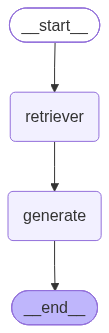

In [37]:
wf

In [40]:
rs=wf.invoke({'ques':'what is COCOMO Model'})

In [41]:
rs['answer']

'From the provided document:\n\n- Definition and origin: COCOMO (Constructive Cost Model) was proposed by Barry Boehm in 1981 based on a study of 63 projects. It is a software cost estimation model.\n\n- Purpose: COCOMO helps predict effort, cost and schedule required for a software development project. Key outcomes it produces are primarily effort and schedule (time).\n\n- Nature: It is a procedural cost-estimate model for software projects and is used to predict project parameters such as size, effort, cost, time and quality.\n\n- Basic COCOMO: A straightforward estimation form that predicts person‑months and development time from project size (KLOC) using:\n  - Effort E = a * (KLOC)^b  (in person‑months)\n  - Development time Tdev = c * (E)^d\n  - Persons required = Effort / Time\n\n- Project types in COCOMO (classification by size, complexity, team experience):\n  - Organic: 2–50 KLOC, low complexity, highly experienced team\n  - Semidetached: 50–300 KLOC, medium complexity, mixed 